# ABC Credit Loan Approval: final notebook (PGAI, Group 11)

**What this notebook does.** It rebuilds our whole project from the original training file and then scores a new CSV file.
Run it top to bottom (Kernel > Restart & Run All). It takes about 2 to 3 minutes.

1. **Cleans** the training data (12 data issues, every fix is logged).
2. **Explores** it (class balance, which fields separate DECLINED from APPROVED).
3. **Builds features** and a preprocessing pipeline (one pipeline, so nothing leaks from the test data).
4. **Trains** a gradient boosting model and checks it (5-fold cross-validation and a hold-out test scored once).
5. **Chooses the cut-off** (threshold) from a business cost curve.
6. **Scores your new CSV file** (Section 9) and saves `predictions.csv`.

**How to test with a new file (3 steps).**
1. Put `training_data.csv` (the original training file) in the same folder as this notebook, or fix `TRAIN_CSV` in Section 1.
2. Put your test file in the same folder and set `TEST_CSV` in Section 1 to its name.
3. Run all cells. Your predictions appear in `predictions.csv`. If your file has a `Decision` column, the notebook also prints accuracy, precision, recall, F1 and the confusion matrix.

**Packages needed:** Python 3.9 or newer, `pandas`, `numpy`, `scikit-learn` (version 1.3 or newer), `matplotlib`. Install with
`pip install pandas numpy scikit-learn matplotlib`.

**Decision rule (same as the chatbot).** The APPROVE or DECLINE label comes only from the trained model's risk score compared with
the threshold. Two fixed policy rules come first and cannot be overruled: age outside 18 to 60 is rejected, and a loan of 100% or more of the vehicle price is rejected. No language model is used.

## 1. Settings (the only cell you normally need to edit)

In [1]:
import os, re, io, csv, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, TargetEncoder

warnings.filterwarnings("ignore")          # keep the output readable
os.environ.setdefault("OMP_NUM_THREADS", "2")

# ---------------------------- FILES ----------------------------
TRAIN_CSV  = "training_data.csv"                 # the original training file given with the project brief
TEST_CSV   = "sample_loan_applications.csv"      # <<< PROF: put the name of the CSV you want to test here
OUTPUT_CSV = "predictions.csv"                   # predictions are written here

# ---------------------------- MODEL SETTINGS (the values we used) ----------------------------
RANDOM_STATE = 42       # fixed seed so every run gives the same numbers (reproducibility)
HOLDOUT_SIZE = 0.20     # 20% of the cleaned data is locked away and scored once
N_FOLDS      = 5        # 5-fold cross-validation
COST_RATIO   = 10       # r: approving a bad loan costs 10x as much as declining a good customer (business assumption)
POLICY_AGE   = (18, 60) # policy range for the applicant's age: outside it the loan is rejected, no exceptions
POLICY_MAX_LTV = 100    # a loan of 100% or more of the vehicle price is rejected up front (no applicant in the data had LTV above 99.6)
SALARY_CAP   = 100_000  # monthly salaries above this (the 99.5th percentile) are capped

# ---------------------------- OPTIONAL EXPERIMENTS ----------------------------
# Field groups to leave OUT of the model. Example: DROP_GROUPS = ["pincode"] trains without any pincode information.
# The groups are: pincode, vehicle, ltv, loan, employment, income, age, past_loans
DROP_GROUPS = []
RUN_PINCODE_EXPERIMENT = False   # True = also compare "with pincode" against "without pincode" (adds about 2 minutes)

def find_file(name):
    """Look for a file in this folder, the parent folder and a few usual places. Returns a Path or raises a clear error."""
    for base in (Path("."), Path(".."), Path("reports"), Path("data")):
        if (base / name).exists():
            return base / name
    raise FileNotFoundError(f"Cannot find '{name}'. Put it in the same folder as this notebook or edit the file names in Section 1.")

print("pandas", pd.__version__, "| numpy", np.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

pandas 3.1.0 | numpy 2.5.4
scikit-learn 1.9.1


## 2. Load the training data and look at it as it is

**Why first?** Good practice is to *observe the data as-is before changing anything*, and to judge its quality *before* cleaning.
Then every fix can be explained and counted. (Course concepts: data exploration, data quality assessment before cleaning.)

In [2]:
raw = pd.read_csv(find_file(TRAIN_CSV), low_memory=False)   # low_memory=False: the Age column holds a stray space in one row
print("Rows, columns:", raw.shape)
display(raw.head(3))

# Quick quality assessment: how many blanks per column, and what is the class mix?
print("\nBlank values per column (only columns that have blanks):")
display(raw.isna().sum()[raw.isna().sum() > 0].to_frame("blank_values"))
print("Class mix in the raw file:")
display(raw["Decision"].value_counts(dropna=False).to_frame("rows").assign(share=lambda t: (t["rows"] / t["rows"].sum()).round(4)))

Rows, columns: (108423, 17)


,ID,Qualifications,Employment_Type,Age,Pincode,Gender,Product_Code,Loan_Amount,LTV,Resident_Type,Net_salary,Final_Tier,Make_Code,Model_Description,Model_Variant,PAST_LOANS_ACTIVE,Decision
0,1.0,SSC,AGR,47,502110.0,Male,MO,59300.0,69.76,O,39000.0,07 Rural,MOPEDS,TVS XL 100 HD ITS BSVI - WINNER EDITION,XL 100CC,PAST_LOANS_ACTIVE,APPROVED
1,2.0,UG,SAL,30,503002.0,Male,MC,153839.0,84.99,O,25000.0,05 Urban,APACHE,APACHE 200 4V 2CH - R MODE BSVI,RTR 200CC,PAST_LOANS_ACTIVE,APPROVED
2,3.0,GRAD,NREGI,24,500090.0,Male,SC,77958.0,64.97,R,35000.0,04 Metro,JUPITER,JUPITER ZX BSVI - AOL - DRUM,110 CC,PAST_LOANS_ACTIVE,APPROVED



Blank values per column (only columns that have blanks):


,blank_values
ID,1
Qualifications,26
Employment_Type,28
Age,19
Pincode,1
Gender,1
Product_Code,1
Loan_Amount,1
LTV,1
Resident_Type,20


Class mix in the raw file:


,rows,share
Decision,,
APPROVED,102724,0.9474
DECLINED,5698,0.0526
NaN,1,0.0000


### Why the class mix matters (class imbalance)

Only about **5% of applications are DECLINED**. A rule that approves everyone would be right about **95% of the time** and would
catch **zero** risky applicants. So *accuracy alone is misleading* on data like this.

**What we did about it (we did NOT copy, delete or re-weight rows):**
1. We judge the model with **recall on DECLINED, precision, PR-AUC and ROC-AUC**, not with accuracy alone.
2. We use a **stratified** split and **stratified** cross-validation, so every part keeps the same 5% decline mix.
3. We choose the decision **threshold** from a **business cost curve** instead of the default 0.5 (a default of 0.5 would decline almost nobody).
4. We also tested a **class-weighted** model (a way of balancing). It did not beat the plain model, so we kept the simpler one.

(Course concepts: accuracy is misleading on imbalanced data; precision and recall; threshold selection; stratified sampling.)

## 3. Data cleaning (12 issues, each one counted and logged)

The brief does not list the data problems, so finding them is part of the work. Imputation (filling blanks) and scaling are **not**
done here. They are done *inside the model pipeline* (Section 5), so that no information from the hold-out data leaks into training.

| # | Issue | What we do |
|---|---|---|
| 1 | One completely empty row | drop it |
| 2 | Rows with 1 to 4 blank fields | keep, add a `missing_any` flag (a blank can itself carry signal), fill later with the median |
| 3 | Age above 60 (policy range is 18 to 60) | keep for training; the chatbot applies the policy rule |
| 4 | LTV equal to 0 (impossible) | set to missing, add `ltv_was_zero` flag |
| 5 | Net salary equal to 0 | valid for students and non-earning members: keep, add `no_income` flag |
| 6 | Salary outliers (up to 980,000 a month) | count them here; cap and log-scale in the feature step |
| 7 | Garbled dash in model names ("â€“") | repair to "-" |
| 8 | Spelling variants ("125 CC DISC" and "125CC DISC") | normalise spacing and case |
| 9 | Duplicate rows (ignoring the ID) | drop exact duplicates; drop both rows when two copies disagree on the outcome |
| 10 | Redundant fields (make decides product, description decides variant) | keep one per level |
| 11 | Confusing labels (the Make field holds model families such as Apache and Jupiter) | note it; the chat now asks brand, then model |
| 12 | 14,000 different pincodes | group by first 2 and 3 digits (binning), encode inside the pipeline |

(Course concepts: missing-value imputation (median for skewed data), missing-value flags, duplicate removal, outlier handling, binning of
high-cardinality fields such as PIN codes, validating odd records before removing them.)

In [3]:
MOJIBAKE = "\u00e2\u20ac\u201c"   # an en dash that was saved as UTF-8 and read back with the wrong encoding

def norm_text(s: pd.Series) -> pd.Series:
    """Fix the garbled dash, unify dashes, spacing and case, and glue digits to 'CC' ('125 CC' -> '125CC')."""
    s = s.astype("string").str.replace(MOJIBAKE, "-", regex=False)
    s = s.str.replace(r"\s*[-\u2013]\s*", " - ", regex=True)
    s = s.str.upper().str.replace(r"(\d+)\s*CC\b", r"\1CC", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

def clean_training(raw: pd.DataFrame):
    """Return (clean data, cleaning log). Every fix is counted so the report can quote the numbers."""
    log = []
    note = lambda issue, rows, action: log.append({"issue": issue, "rows_affected": int(rows), "action": action})
    df = raw.copy()

    # text columns: trim spaces and turn empty strings into real blanks
    for c in df.select_dtypes(exclude="number").columns:
        df[c] = df[c].astype("string").str.strip().replace("", pd.NA)

    # 1. fully empty row (its Age holds a space, so a plain dropna would have missed it)
    empty = df.isna().all(axis=1)
    df = df[~empty].copy()
    note("1 empty row", empty.sum(), "dropped")

    df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
    df["Pincode"] = df["Pincode"].astype("Int64")

    # 2. blank fields: keep the row, remember that something was missing (imputed later inside the pipeline)
    feat_cols = [c for c in df.columns if c not in ("ID", "Decision")]
    df["missing_any"] = df[feat_cols].isna().any(axis=1).astype(int)
    note("2 blank fields", df["missing_any"].sum(), "kept, missing_any flag, filled in the pipeline")

    # 3. age above 60: keep for training
    note("3 Age > 60", (df["Age"] > 60).sum(), "kept; the age policy rule is applied at scoring time")

    # 4. LTV = 0 is impossible, so treat as missing and flag it
    ltv0 = df["LTV"] == 0
    df.loc[ltv0, "LTV"] = np.nan
    df["ltv_was_zero"] = ltv0.astype(int)
    note("4 LTV = 0", ltv0.sum(), "set to missing + ltv_was_zero flag")

    # 5. zero salary is valid for students and non-earning family members
    df["no_income"] = (df["Net_salary"] == 0).astype(int)
    note("5 Net_salary = 0", df["no_income"].sum(), "kept + no_income flag")

    # 6. salary outliers (only counted here; the cap is applied when features are built)
    p995 = df["Net_salary"].quantile(0.995)
    note("6 salary outliers", (df["Net_salary"] > p995).sum(), f"above the 99.5th percentile ({p995:,.0f}); capped later at {SALARY_CAP:,}")

    # 7 and 8. garbled dash and spelling variants in the vehicle text columns
    moji = df["Model_Description"].str.contains(MOJIBAKE, regex=False, na=False)
    note("7 garbled text", moji.sum(), "repaired")
    before = df["Model_Variant"].nunique(), df["Model_Description"].nunique()
    for c in ("Model_Description", "Model_Variant"):
        df[c] = norm_text(df[c])
    note("8 spelling variants", 0, f"normalised: Model_Variant {before[0]} -> {df['Model_Variant'].nunique()} values")

    # 9. duplicates ignoring the ID. Exact copies: keep the first. Copies that DISAGREE on the outcome would teach the model a
    #    contradiction, so both are dropped (only when no field is blank, because blanks may explain a difference).
    key = [c for c in df.columns if c not in ("ID", "missing_any", "ltv_was_zero", "no_income")]
    key_nolabel = [c for c in key if c != "Decision"]
    n_outcomes = df.groupby(key_nolabel, dropna=False)["Decision"].transform("nunique")
    dup_any = df.duplicated(subset=key_nolabel, keep=False)
    conflict = dup_any & (n_outcomes > 1) & (df["missing_any"] == 0)
    plain_dup = df.duplicated(subset=key, keep="first") & ~conflict
    df = df[~conflict & ~plain_dup].copy()
    note("9 duplicates", plain_dup.sum(), "dropped (kept first)")
    note("9 conflicting duplicates", conflict.sum(), "dropped (the outcomes disagreed)")

    # 12. pincode prefixes (binning): 14,000 pincodes are too many values, the first 2 and 3 digits are stable regions
    pin = df["Pincode"].astype("string")
    df["pin2"], df["pin3"] = pin.str[:2], pin.str[:3]
    return df.reset_index(drop=True), pd.DataFrame(log)

df_clean, cleaning_log = clean_training(raw)
print(f"{len(raw):,} raw rows -> {len(df_clean):,} clean rows")
display(cleaning_log)

108,423 raw rows -> 108,405 clean rows


,issue,rows_affected,action
0,1 empty row,1,dropped
1,2 blank fields,81,"kept, missing_any flag, filled in the pipeline"
2,3 Age > 60,1105,kept; the age policy rule is applied at scorin...
3,4 LTV = 0,65,set to missing + ltv_was_zero flag
4,5 Net_salary = 0,626,kept + no_income flag
5,6 salary outliers,420,"above the 99.5th percentile (100,000); capped ..."
6,7 garbled text,5028,repaired
7,8 spelling variants,0,normalised: Model_Variant 21 -> 20 values
8,9 duplicates,12,dropped (kept first)
9,9 conflicting duplicates,5,dropped (the outcomes disagreed)


## 4. Exploratory data analysis: which fields separate DECLINED from APPROVED?

We look at the decline rate for slices of each field. A field whose decline rate changes a lot between slices carries signal.
These charts decide which questions the chatbot must ask (course concepts: EDA, relationship of each field to the target).

Overall decline rate: 5.25%   |   'approve everyone' accuracy: 94.75%


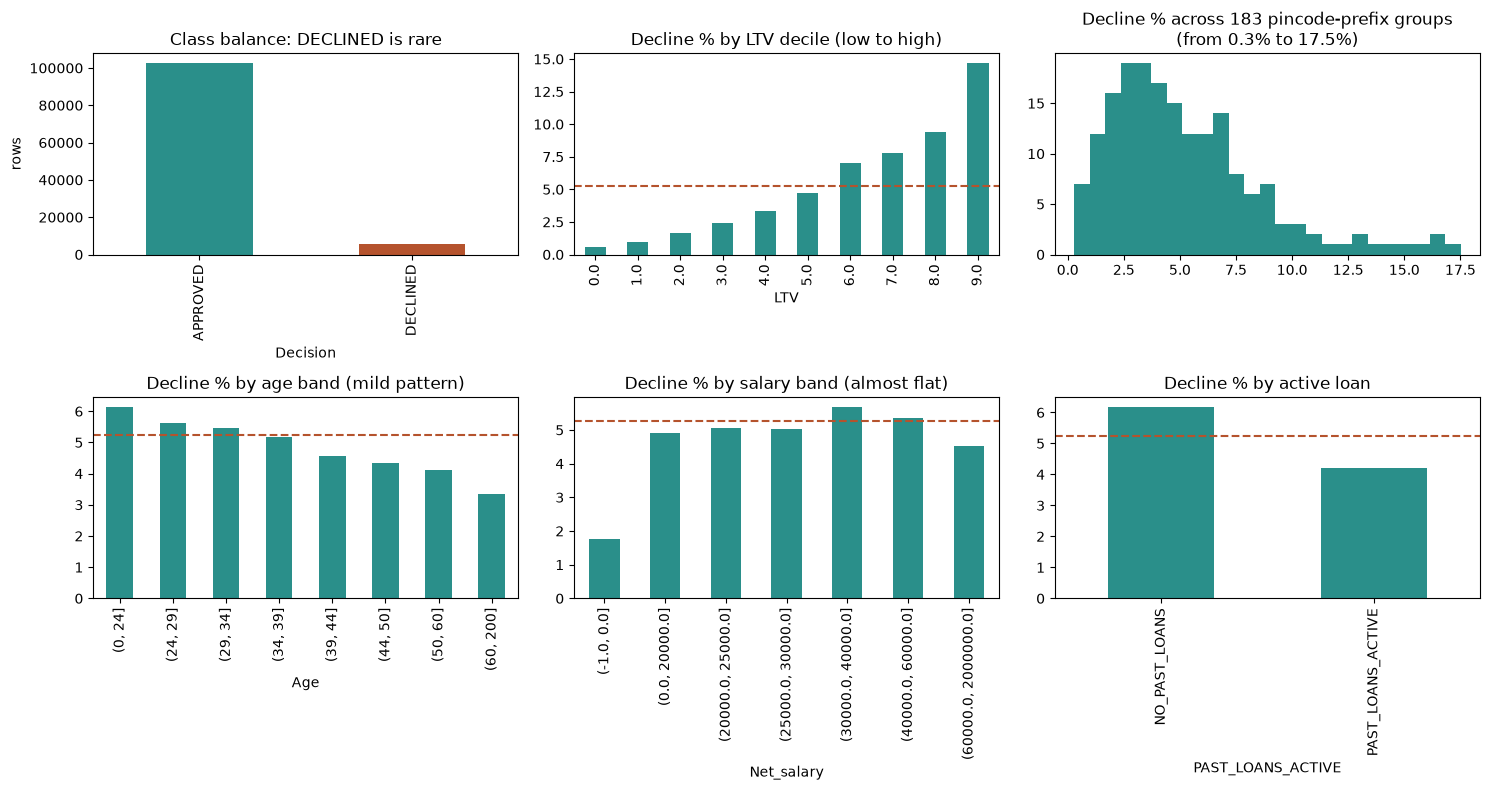

In [4]:
d = df_clean.copy()
d["declined"] = (d["Decision"] == "DECLINED").astype(int)
overall = d["declined"].mean()
print(f"Overall decline rate: {overall:.2%}   |   'approve everyone' accuracy: {1 - overall:.2%}")

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

# (a) class balance
d["Decision"].value_counts().plot.bar(ax=axs[0, 0], color=["#2a8f8a", "#b5532d"])
axs[0, 0].set_title("Class balance: DECLINED is rare"); axs[0, 0].set_ylabel("rows")

# (b) LTV deciles: the strongest pattern
q = pd.qcut(d["LTV"], 10, labels=False, duplicates="drop")
(d.groupby(q)["declined"].mean() * 100).plot.bar(ax=axs[0, 1], color="#2a8f8a")
axs[0, 1].axhline(overall * 100, color="#b5532d", ls="--"); axs[0, 1].set_title("Decline % by LTV decile (low to high)")

# (c) pincode prefix (3 digits): groups with at least 200 applications
p3 = d.groupby("pin3")["declined"].agg(["mean", "size"]); p3 = p3[p3["size"] >= 200]
axs[0, 2].hist(p3["mean"] * 100, bins=25, color="#2a8f8a")
axs[0, 2].set_title(f"Decline % across {len(p3)} pincode-prefix groups\n(from {p3['mean'].min():.1%} to {p3['mean'].max():.1%})")

# (d) age bands
ab = pd.cut(d["Age"], [0, 24, 29, 34, 39, 44, 50, 60, 200])
(d.groupby(ab, observed=True)["declined"].mean() * 100).plot.bar(ax=axs[1, 0], color="#2a8f8a")
axs[1, 0].axhline(overall * 100, color="#b5532d", ls="--"); axs[1, 0].set_title("Decline % by age band (mild pattern)")

# (e) salary bands
sb = pd.cut(d["Net_salary"], [-1, 0, 20000, 25000, 30000, 40000, 60000, 2e6])
(d.groupby(sb, observed=True)["declined"].mean() * 100).plot.bar(ax=axs[1, 1], color="#2a8f8a")
axs[1, 1].axhline(overall * 100, color="#b5532d", ls="--"); axs[1, 1].set_title("Decline % by salary band (almost flat)")

# (f) active past loan
(d.groupby("PAST_LOANS_ACTIVE")["declined"].mean() * 100).plot.bar(ax=axs[1, 2], color="#2a8f8a")
axs[1, 2].axhline(overall * 100, color="#b5532d", ls="--"); axs[1, 2].set_title("Decline % by active loan")
plt.tight_layout(); plt.show()

**What the charts say.** The decline rate climbs steadily with LTV (the loan as a share of the vehicle price). Pincode groups differ a lot
(from under 1% to about 17%). Age shows only a mild pattern (younger applicants are declined a bit more) and salary is almost flat.
This agrees with the importance test in Section 7.

## 5. Feature engineering and the preprocessing pipeline

**Cross-features** (ratios and differences of existing fields) often say more than the raw numbers:
- `vehicle_value = Loan_Amount / (LTV / 100)` and `down_payment = vehicle_value - Loan_Amount`
- `LTI = Loan_Amount / Net_salary` (loan relative to income)
- `log_salary`: salary is very skewed (skewness about 16), so we cap it at the 99.5th percentile and take the log.

**Fields are grouped by chatbot question**, so we can test what happens when a whole question is removed (Section 7).

**Everything that learns from data sits inside one scikit-learn `Pipeline`**: filling blanks with the median (best for skewed data), one-hot
encoding of categories (rare categories are pooled, new unseen categories are ignored safely), and a smoothed *target encoding* of the pincode
prefixes (each prefix is replaced by its past decline rate, computed in cross-fitted folds so it cannot leak the answer).
Because the pipeline is fitted only on training rows, the hold-out and any new test file are never used for learning.

(Course concepts: cross-features, skew and the median, one-hot / dummy variables, binning, data leakage, stratified split before scaling.)

In [5]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Stateless feature builder (the same code is used for the training data and for any new file)."""
    out = df.copy()
    cats = ["Final_Tier", "Make_Code", "Product_Code", "Model_Variant", "Employment_Type", "PAST_LOANS_ACTIVE",
            "Gender", "Qualifications", "Resident_Type", "pin2", "pin3"]
    for c in cats:   # blanks become the word MISSING so the encoders can treat them as a category
        if c in out:
            out[c] = out[c].astype(object).where(out[c].notna(), "MISSING").astype(str)
    sal = out["Net_salary"].astype(float).clip(upper=SALARY_CAP)
    ltv, loan = out["LTV"].astype(float), out["Loan_Amount"].astype(float)
    out["log_salary"] = np.log1p(sal)
    out["vehicle_value"] = loan / (ltv / 100.0)
    out["down_payment"] = out["vehicle_value"] - loan
    out["LTI"] = loan / sal.where(sal > 0)
    for c in ("Age", "LTV", "Loan_Amount"):
        out[c] = out[c].astype(float)
    return out

# Field groups = the 7 chatbot questions. 'num' = numbers, 'onehot' = categories, 'te' = target-encoded prefixes.
GROUPS = {
    "pincode":    {"onehot": ["Final_Tier"], "te": ["pin2", "pin3"]},
    "vehicle":    {"onehot": ["Make_Code", "Product_Code", "Model_Variant"]},
    "ltv":        {"num": ["LTV", "ltv_was_zero"]},
    "loan":       {"num": ["Loan_Amount", "vehicle_value", "down_payment"]},
    "employment": {"onehot": ["Employment_Type"]},
    "income":     {"num": ["log_salary", "no_income", "LTI"]},
    "age":        {"num": ["Age"]},
    "past_loans": {"onehot": ["PAST_LOANS_ACTIVE"]},
}
ACTIVE_GROUPS = {k: v for k, v in GROUPS.items() if k not in DROP_GROUPS}
print("Field groups used by the model:", list(ACTIVE_GROUPS))

def build_preprocessor(groups: dict, scale=None) -> ColumnTransformer:
    num, onehot, te = ["missing_any"], [], []
    for g in groups.values():
        num += g.get("num", []); onehot += g.get("onehot", []); te += g.get("te", [])
    num_step = SimpleImputer(strategy="median")                    # blanks -> median (robust for skewed numbers)
    if scale == "quantile":                                         # only the linear model needs this; trees do not
        num_step = Pipeline([("fill", num_step), ("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=RANDOM_STATE))])
    parts = [("num", num_step, num)]
    if onehot:
        parts.append(("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), onehot))
    if te:
        parts.append(("target_enc", TargetEncoder(target_type="binary", smooth="auto",
                                                  cv=N_FOLDS, shuffle=True, random_state=RANDOM_STATE), te))  # int cv works in every scikit-learn 1.3+ (same stratified folds)
    return ColumnTransformer(parts, remainder="drop")

def make_gradient_boosting(groups=None) -> Pipeline:
    """Our final model: gradient boosting (many small trees, each one fixing the mistakes of the earlier ones)."""
    return Pipeline([("prep", build_preprocessor(groups or ACTIVE_GROUPS)),
                     ("clf", HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=15, min_samples_leaf=200,
                                                            max_iter=200, random_state=RANDOM_STATE))])

def make_logistic(groups=None) -> Pipeline:
    """A simple baseline to compare against."""
    return Pipeline([("prep", build_preprocessor(groups or ACTIVE_GROUPS, scale="quantile")),
                     ("clf", LogisticRegression(max_iter=1000))])

Field groups used by the model: ['pincode', 'vehicle', 'ltv', 'loan', 'employment', 'income', 'age', 'past_loans']


## 6. Split the data and compare models

**Stratified 80/20 split.** 20% of the rows are locked away as a **hold-out test** and scored **once**, at the very end. The split is *stratified*
(each part keeps the same 5% DECLINED share) and happens *before* any learning (course concepts: train/validation split, stratified sampling, no leakage).

**5-fold stratified cross-validation** on the 80% part gives honest *out-of-fold* scores: each row is scored by a model that never saw it
(course concepts: overfitting and underfitting, generalisation).

We compare **logistic regression** (a simple linear model) with **gradient boosting**. Metrics:
- **ROC-AUC**: how well the model ranks risky above safe applicants, independent of any cut-off (0.5 = guessing).
- **PR-AUC**: the same, but focused on the rare DECLINED class (guessing scores about 0.05, the decline rate).

In [6]:
data = add_features(df_clean)
y_all = (data["Decision"] == "DECLINED").astype(int)

# stratified hold-out split, fixed seed
_, hold_idx = train_test_split(data.index, test_size=HOLDOUT_SIZE, stratify=y_all, random_state=RANDOM_STATE)
is_hold = data.index.isin(hold_idx)                     # True for the locked-away rows; both parts keep the original file order
X_train, y_train = data[~is_hold].reset_index(drop=True), y_all[~is_hold].reset_index(drop=True)
X_hold,  y_hold  = data[is_hold].reset_index(drop=True),  y_all[is_hold].reset_index(drop=True)
print(f"train {len(X_train):,} rows | hold-out {len(X_hold):,} rows | DECLINED share train {y_train.mean():.4f}, hold-out {y_hold.mean():.4f}")

cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rows, oof = [], {}
for name, maker in [("Logistic regression", make_logistic), ("Gradient boosting (our model)", make_gradient_boosting)]:
    t0 = time.time()
    p = cross_val_predict(maker(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]   # out-of-fold scores
    oof[name] = p
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_train, p), "PR-AUC": average_precision_score(y_train, p),
                 "seconds": time.time() - t0})
display(pd.DataFrame(rows).round(4))
print(f"A random guess would score PR-AUC about {y_train.mean():.3f}.")

train 86,724 rows | hold-out 21,681 rows | DECLINED share train 0.0525, hold-out 0.0525


,model,ROC-AUC,PR-AUC,seconds
0,Logistic regression,0.7748,0.1637,3.4106
1,Gradient boosting (our model),0.7784,0.1708,7.4202


A random guess would score PR-AUC about 0.053.


## 7. Which fields matter? (feature-group importance)

**Method.** On the hold-out set we *scramble* one field group at a time (shuffle its values among the rows) and measure how much the model's
ROC-AUC drops. A big drop means the model relied on that group. (Course concept: feature importance. This is the same idea as the
importance ranking you get from a random forest, but done per chatbot question and without retraining.)

**Reading it.**
- **LTV (and the loan amount that goes with it)** is by far the strongest signal.
- **Pincode** is second. It works as a stand-in for local history, so it reflects past decisions in an area and not a cause.
- **Age, income, employment, vehicle and past loans** each add little on their own.

,field group,ROC-AUC drop
0,ltv,0.1828
1,pincode,0.0568
2,vehicle,0.0101
3,loan,0.0095
4,past_loans,0.0071
5,age,0.0049
6,employment,0.0028
7,income,0.0007


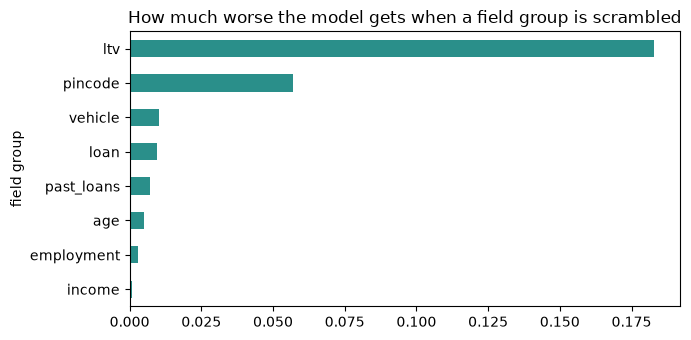

In [7]:
final_model = make_gradient_boosting().fit(X_train, y_train)      # fitted on the training part only
p_hold = final_model.predict_proba(X_hold)[:, 1]
base_auc = roc_auc_score(y_hold, p_hold)

def group_columns(g):
    return [c for key in ("onehot", "te", "num") for c in ACTIVE_GROUPS[g].get(key, [])]

rng = np.random.RandomState(RANDOM_STATE)
imp = []
for g in ACTIVE_GROUPS:
    drops = []
    for _ in range(3):                                            # 3 shuffles, average the drop
        shuffled = X_hold.copy()
        order = rng.permutation(len(shuffled))
        cols = group_columns(g)
        shuffled[cols] = shuffled[cols].iloc[order].to_numpy()    # shuffle the whole group together
        drops.append(base_auc - roc_auc_score(y_hold, final_model.predict_proba(shuffled)[:, 1]))
    imp.append({"field group": g, "ROC-AUC drop": float(np.mean(drops))})
imp = pd.DataFrame(imp).sort_values("ROC-AUC drop", ascending=False).reset_index(drop=True)
display(imp.round(4))
imp.set_index("field group")["ROC-AUC drop"].sort_values().plot.barh(color="#2a8f8a", figsize=(7, 3.5))
plt.title("How much worse the model gets when a field group is scrambled"); plt.tight_layout(); plt.show()

In [8]:
# OPTIONAL: does the pincode really deserve its place? Compare the model with and without pincode information.
# Set RUN_PINCODE_EXPERIMENT = True in Section 1 to run it (about 2 minutes). Results we measured on the training part:
#   full model (tier + 2- and 3-digit prefixes)  ROC-AUC 0.7784, PR-AUC 0.1708
#   tier + 2-digit prefix only                   ROC-AUC 0.7754, PR-AUC 0.1662
#   no pincode information at all                ROC-AUC 0.7600, PR-AUC 0.1506
#   the 7 area tiers only (no prefixes)          ROC-AUC 0.7599, PR-AUC 0.1509
# So the signal sits in the regional prefixes, not in the 7 tiers.
if RUN_PINCODE_EXPERIMENT:
    variants = {
        "full model": ACTIVE_GROUPS,
        "tier + 2-digit prefix": {**ACTIVE_GROUPS, "pincode": {"onehot": ["Final_Tier"], "te": ["pin2"]}},
        "no pincode at all": {k: v for k, v in ACTIVE_GROUPS.items() if k != "pincode"},
    }
    out = []
    for name, grp in variants.items():
        p = cross_val_predict(make_gradient_boosting(grp), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        out.append({"variant": name, "ROC-AUC": roc_auc_score(y_train, p), "PR-AUC": average_precision_score(y_train, p)})
    display(pd.DataFrame(out).round(4))
else:
    print("Skipped (RUN_PINCODE_EXPERIMENT is False). The measured results are listed in the comments above.")

Skipped (RUN_PINCODE_EXPERIMENT is False). The measured results are listed in the comments above.


## 8. Choose the cut-off from a cost curve, then score the hold-out set once

The model returns a **risk score** between 0 and 1. We must pick a **cut-off**: decline when the score is at or above it. This is a business trade-off:
- a **stricter** cut-off (low number) declines many good customers (lost margin);
- a **looser** cut-off (high number) approves many risky ones (credit loss).

We assume a bad loan we approve costs **r = 10 times** what we lose by declining a good customer (a business judgement; a real lender uses its own figures).
For each possible cut-off we compute the cost per 1,000 applications on the **out-of-fold** scores and take the lowest point.
The default of 0.5 would be wrong here, because only 5% of applications are declined and almost no score reaches 0.5
(course concept: imbalanced data may need threshold tuning beyond the default).

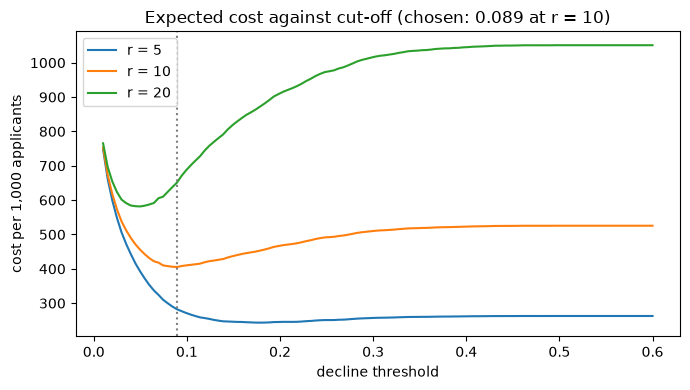

Chosen threshold: 0.089
Cost per 1,000 applicants: 405 with our model, against 525 if we approved everyone.


In [9]:
p = oof["Gradient boosting (our model)"]; y = y_train.to_numpy(); n = len(y)
thresholds = np.linspace(0.01, 0.60, 120)

def cost_per_1000(t, r=COST_RATIO):
    decline = p >= t
    missed_bad = ((~decline) & (y == 1)).sum()        # risky applicants we approved
    lost_good  = (decline & (y == 0)).sum()           # good customers we declined
    return (missed_bad * r + lost_good) / n * 1000

fig, ax = plt.subplots(figsize=(7, 4))
for r, colr in [(5, "#1f77b4"), (10, "#ff7f0e"), (20, "#2ca02c")]:
    ax.plot(thresholds, [cost_per_1000(t, r) for t in thresholds], label=f"r = {r}", color=colr)
costs = np.array([cost_per_1000(t) for t in thresholds])
THRESHOLD = round(float(thresholds[costs.argmin()]), 3)      # rounded to 3 decimals, as used in the chatbot
ax.axvline(THRESHOLD, color="grey", ls=":"); ax.set_xlabel("decline threshold"); ax.set_ylabel("cost per 1,000 applicants")
ax.set_title(f"Expected cost against cut-off (chosen: {THRESHOLD:.3f} at r = {COST_RATIO})"); ax.legend(); plt.tight_layout(); plt.show()

approve_all = y.sum() * COST_RATIO / n * 1000
print(f"Chosen threshold: {THRESHOLD:.3f}")
print(f"Cost per 1,000 applicants: {costs.min():.0f} with our model, against {approve_all:.0f} if we approved everyone.")

,hold-out
ROC-AUC,0.7829
PR-AUC,0.1822
Accuracy,0.8157
Precision (DECLINED),0.1513
Recall (DECLINED),0.5443
F1 (DECLINED),0.2368


Confusion matrix:  approved correctly 17,065 | good customers declined 3,477 | risky applicants missed 519 | risky applicants caught 620
With the policy rules (214 hold-out rows hit, all by the age rule; none has LTV of 100%): accuracy 0.8076, precision 0.1460, recall 0.5487
'Approve everyone' accuracy would be 94.75% with recall 0%. Our accuracy is lower on purpose: we decline about 19% of applications to catch 54% of the risky ones.


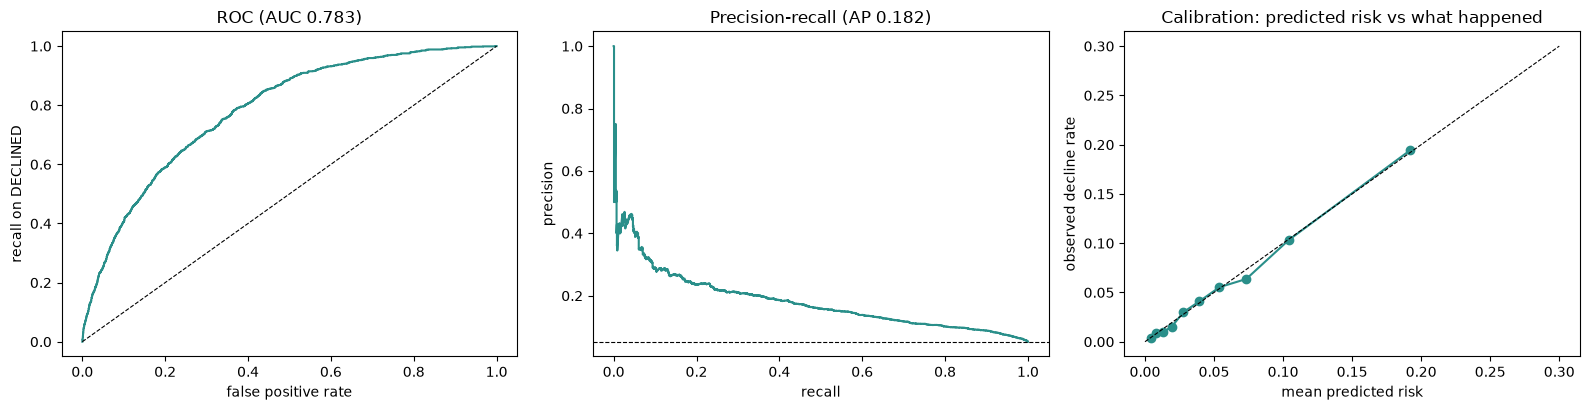

In [10]:
# ----- hold-out set, scored once, at the chosen threshold -----
pred_hold = (p_hold >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_hold, pred_hold).ravel()
metrics = {
    "ROC-AUC": roc_auc_score(y_hold, p_hold), "PR-AUC": average_precision_score(y_hold, p_hold),
    "Accuracy": accuracy_score(y_hold, pred_hold), "Precision (DECLINED)": precision_score(y_hold, pred_hold),
    "Recall (DECLINED)": recall_score(y_hold, pred_hold), "F1 (DECLINED)": f1_score(y_hold, pred_hold),
}
display(pd.Series(metrics).round(4).to_frame("hold-out"))
print(f"Confusion matrix:  approved correctly {tn:,} | good customers declined {fp:,} | risky applicants missed {fn:,} | risky applicants caught {tp:,}")
# The same rules are applied in the chatbot and in score_file(). Their effect on this hold-out set:
rule_hold = ((~X_hold["Age"].between(*POLICY_AGE)) & X_hold["Age"].notna()) | (X_hold["LTV"] >= POLICY_MAX_LTV)
pred_sys = np.where(rule_hold, 1, pred_hold)
print(f"With the policy rules ({int(rule_hold.sum())} hold-out rows hit, all by the age rule; none has LTV of 100%): accuracy {accuracy_score(y_hold, pred_sys):.4f}, "
      f"precision {precision_score(y_hold, pred_sys):.4f}, recall {recall_score(y_hold, pred_sys):.4f}")
print(f"'Approve everyone' accuracy would be {1 - y_hold.mean():.2%} with recall 0%. Our accuracy is lower on purpose: we decline "
      f"about {pred_hold.mean():.0%} of applications to catch {recall_score(y_hold, pred_hold):.0%} of the risky ones.")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
fpr, tpr, _ = roc_curve(y_hold, p_hold)
axs[0].plot(fpr, tpr, color="#2a8f8a"); axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[0].set_title(f"ROC (AUC {metrics['ROC-AUC']:.3f})")
axs[0].set_xlabel("false positive rate"); axs[0].set_ylabel("recall on DECLINED")
pr, rc, _ = precision_recall_curve(y_hold, p_hold)
axs[1].plot(rc, pr, color="#2a8f8a"); axs[1].axhline(y_hold.mean(), color="k", ls="--", lw=0.8); axs[1].set_title(f"Precision-recall (AP {metrics['PR-AUC']:.3f})")
axs[1].set_xlabel("recall"); axs[1].set_ylabel("precision")
# calibration: when the model says 10%, do about 10% of those applicants really get declined?
bins = pd.qcut(p_hold, 10, duplicates="drop")
cal = pd.DataFrame({"pred": p_hold, "actual": y_hold}).groupby(bins, observed=True).mean()
axs[2].plot(cal["pred"], cal["actual"], "o-", color="#2a8f8a"); axs[2].plot([0, 0.3], [0, 0.3], "k--", lw=0.8)
axs[2].set_title("Calibration: predicted risk vs what happened"); axs[2].set_xlabel("mean predicted risk"); axs[2].set_ylabel("observed decline rate")
plt.tight_layout(); plt.show()

## 9. Score a new CSV file (this is the section to use for testing)

`score_file()` reads **any** CSV in the training-file layout and returns one row per input row, in the same order:

| Output column | Meaning |
|---|---|
| `ID` | the ID from your file (or 1, 2, 3 ... if there is none) |
| `Decision` | **the final answer, APPROVED or DECLINED.** Two fixed policy rules come first and cannot be overruled: age outside 18 to 60, and a loan of 100% or more of the vehicle price. Those rows are DECLINED. Every other row gets the model's label (risk score compared with the threshold). |
| `P_DECLINED` | the model's risk score (0 to 1) |
| `Reason` | `Model`, or `Policy rule: ...` with the rule that fired |
| `Model_Decision` | what the model alone would have said |
| `policy_age_ok` | `True` if the age is between 18 and 60 (blank ages count as OK) |

**It understands everyday headers too** (`Income`, `Cost of vehicle`, `Loan Required`, `Make`, `Model`, `Occupation`, `Existing loan`, `Pin code` ...): LTV is worked out from the cost and the loan, an `Income` column that looks annual (median above 150,000) is divided by 12, and vehicle names are matched to our vehicle list. Every interpretation is listed as a warning, so read the warnings.

**It is forgiving about file format**: any delimiter (comma, semicolon, tab, pipe), any encoding, any header case or column order, missing columns
(filled with typical values and reported), numbers written like `25,000`, `Rs. 25000` or `30 years`, Yes/No for the active-loan column, and
categories it has never seen (scored with the typical profile). Every repair is listed as a warning.
Rows are never dropped.

If your file has a `Decision` column (APPROVED or DECLINED), the notebook also prints accuracy, precision, recall, F1, ROC-AUC and the confusion matrix.

**What if the file has extra columns, such as a CIBIL score, ITR (tax return) fields, PAN or Aadhaar numbers?**
The model was trained only on the columns of the training file, so it cannot use anything else. Extra columns are **ignored and listed in a warning**; they never
cause an error and never change a prediction. (To make the model use a CIBIL score we would have to retrain it on past applications that contain that score
and their outcomes, which the training file does not have.) If a column the model *does* need is missing (for example `Net_salary` is replaced by an ITR income
column), the file still scores: the missing field is filled with a typical value and the warning says so, but the predictions are then less reliable.
Try `sample_with_extra_columns.csv` (the sample file plus CIBIL and ITR columns) to see this.

In [11]:
import difflib

RAW_COLS = ["ID", "Qualifications", "Employment_Type", "Age", "Pincode", "Gender", "Product_Code", "Loan_Amount", "LTV",
            "Resident_Type", "Net_salary", "Final_Tier", "Make_Code", "Model_Description", "Model_Variant", "PAST_LOANS_ACTIVE", "Decision"]
MODEL_COLS = ["Pincode", "Make_Code", "Product_Code", "Model_Variant", "LTV", "Loan_Amount", "Employment_Type", "Net_salary", "Age", "PAST_LOANS_ACTIVE"]

EMPLOYMENT_LABELS = {"SAL": "Salaried", "SEP": "Self-employed", "NPP": "Non-permanent probationary", "AGR": "Agriculture / farming",
                     "NREGI": "Non-regular income", "PEN": "Pensioner", "STU": "Student", "NONEARNMEM": "Non-earning family member"}
# everyday words people write in the employment column -> our codes (letters only, upper case)
EMP_WORDS = {re.sub(r"[^A-Z]", "", lab.upper()): code for code, lab in EMPLOYMENT_LABELS.items()}
EMP_WORDS.update({"SALARIED": "SAL", "SERVICE": "SAL", "EMPLOYEE": "SAL", "SELFEMPLOYED": "SEP", "BUSINESS": "SEP", "SELFEMPLOYEDPROFESSIONAL": "SEP",
                  "AGRICULTURE": "AGR", "FARMER": "AGR", "FARMING": "AGR", "PENSION": "PEN", "RETIRED": "PEN", "STUDENT": "STU",
                  "HOUSEWIFE": "NONEARNMEM", "HOMEMAKER": "NONEARNMEM", "NONEARNING": "NONEARNMEM", "PROBATION": "NPP", "NONREGULAR": "NREGI"})

# Friendly header names people use in their own files -> the names the model knows (compared without spaces, case or punctuation).
# "Income", "Make", "Model", "Cost of vehicle" and "Loan Required" need a little interpretation, see score_file().
ALIASES = {
    "applicantage": "Age", "ageinyears": "Age",
    "pin": "Pincode", "pincodeofapplicant": "Pincode", "postalcode": "Pincode", "zip": "Pincode", "zipcode": "Pincode",
    "income": "Income_Generic", "annualincome": "Income_Annual", "yearlyincome": "Income_Annual", "incomeperannum": "Income_Annual",
    "grossannualincome": "Income_Annual", "monthlyincome": "Net_salary", "netmonthlyincome": "Net_salary", "monthlysalary": "Net_salary",
    "netsalary": "Net_salary", "salary": "Net_salary",
    "costofvehicle": "Vehicle_Price", "vehiclecost": "Vehicle_Price", "vehicleprice": "Vehicle_Price", "onroadprice": "Vehicle_Price",
    "exshowroomprice": "Vehicle_Price", "price": "Vehicle_Price", "vehiclevalue": "Vehicle_Price",
    "loanrequired": "Loan_Amount", "loanamount": "Loan_Amount", "loan": "Loan_Amount", "loanrequested": "Loan_Amount",
    "requestedloan": "Loan_Amount", "loanrequirement": "Loan_Amount",
    "loantovalue": "LTV", "ltvpercent": "LTV",
    "make": "Make_Input", "brand": "Make_Input", "manufacturer": "Make_Input",
    "model": "Model_Input", "vehiclemodel": "Model_Input", "vehicle": "Model_Input",
    "employment": "Employment_Type", "employmenttype": "Employment_Type", "occupation": "Employment_Type", "profession": "Employment_Type",
    "activeloan": "PAST_LOANS_ACTIVE", "existingloan": "PAST_LOANS_ACTIVE", "anyactiveloan": "PAST_LOANS_ACTIVE",
    "pastloansactive": "PAST_LOANS_ACTIVE", "activepastloan": "PAST_LOANS_ACTIVE", "hasactiveloan": "PAST_LOANS_ACTIVE",
    "decision": "Decision", "loanstatus": "Decision", "outcome": "Decision",
}
INTERNAL = {"Income_Generic", "Income_Annual", "Vehicle_Price", "Make_Input", "Model_Input"}
FRIENDLY = {"Income_Generic": "income", "Income_Annual": "annual income", "Vehicle_Price": "vehicle price", "Make_Input": "vehicle brand",
            "Model_Input": "vehicle model", "Net_salary": "monthly income", "Loan_Amount": "loan amount", "Employment_Type": "employment type",
            "PAST_LOANS_ACTIVE": "active loan", "Pincode": "pincode", "Age": "age", "Decision": "decision", "LTV": "loan-to-value"}

# ---- lookup tables learned from the training data: pincode -> area tier, and the vehicle list ----
_pt = df_clean.dropna(subset=["Pincode", "Final_Tier"])
PIN_TIER = {int(k): v for k, v in _pt.groupby("Pincode")["Final_Tier"].first().items()}
PIN3_TIER = _pt.assign(p3=_pt["Pincode"].astype(str).str[:3]).groupby("p3")["Final_Tier"].agg(lambda s: s.value_counts().index[0]).to_dict()
KNOWN_MAKES = set(df_clean["Make_Code"].dropna().unique())
_veh = (df_clean.dropna(subset=["Model_Description", "Make_Code", "Product_Code", "Model_Variant"])
        .groupby("Model_Description")[["Make_Code", "Product_Code", "Model_Variant"]].first().reset_index())
VEHICLES = [{"desc": r.Model_Description, "make": r.Make_Code, "product": r.Product_Code, "variant": r.Model_Variant} for r in _veh.itertuples()]

def _key(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

def read_any_csv(path) -> pd.DataFrame:
    """Read a CSV tolerantly: any encoding, any delimiter, any header case, friendly header names. Everything is read as text first."""
    raw_bytes = Path(path).read_bytes()
    text = None
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            text = raw_bytes.decode(enc); break
        except UnicodeDecodeError:
            continue
    if not text or not text.strip():
        raise ValueError("The file is empty.")
    try:
        sep = csv.Sniffer().sniff(text[:20000], delimiters=",;\t|").delimiter
    except csv.Error:
        sep = ","
    frame = pd.read_csv(io.StringIO(text), dtype=str, sep=sep, engine="python", on_bad_lines="skip", skip_blank_lines=False)
    canon = {c.lower(): c for c in RAW_COLS}
    names, renamed = [], {}
    for c in frame.columns:
        c0 = str(c).strip()
        exact = canon.get(c0.lower().replace(" ", "_"))
        new = exact or ALIASES.get(_key(c0), c0)
        if new != c0 and not exact:
            renamed[c0] = new
        names.append(new)
    frame.columns = names
    out = frame.loc[:, ~pd.Index(names).duplicated()].copy()
    out.attrs["renamed"] = renamed
    return out

def to_number(col: pd.Series) -> pd.Series:
    """'25,000', 'Rs. 25000', '30 years', '80%' -> numbers. Anything else, negatives and infinities -> blank."""
    t = col.astype("string").str.strip()
    t = t.str.replace(r"(?i)\b(rs\.?|inr|rupees?|yrs?|years?)", "", regex=True).str.replace(r"[₹,%\s]", "", regex=True)
    out = pd.to_numeric(t, errors="coerce").astype(float)
    out[~np.isfinite(out) | (out < 0)] = np.nan
    return out

def _norm_vehicle(t):
    t = re.sub(r"[^A-Z0-9 ]", " ", str(t).upper())
    t = re.sub(r"\bBS\s*(VI|6)\b", "BSVI", t)
    t = re.sub(r"\bTVS\b", " ", t)
    return " ".join(t.split())

def match_vehicle(model_text, make_text):
    """(make, product, variant, how) for a vehicle named in plain words. how: exact, close, family or none."""
    norm = {_norm_vehicle(v["desc"]): v for v in VEHICLES}
    m = _norm_vehicle(model_text) if pd.notna(model_text) and str(model_text).strip() else ""
    if m:
        if m in norm:
            v = norm[m]; return v["make"], v["product"], v["variant"], "exact"
        close = difflib.get_close_matches(m, list(norm), n=1, cutoff=0.6)
        if close:
            v = norm[close[0]]; return v["make"], v["product"], v["variant"], "close"
    mk = _norm_vehicle(make_text) if pd.notna(make_text) and str(make_text).strip() else ""
    for cand in (mk, m.split(" ")[0] if m else ""):
        if cand and any(v["make"] == cand for v in VEHICLES):
            prods = [v["product"] for v in VEHICLES if v["make"] == cand]
            return cand, max(set(prods), key=prods.count), "OTHER", "family"
    return pd.NA, pd.NA, pd.NA, "none"

def score_file(path, threshold=None):
    """Score a CSV file. Returns (result table, list of warnings)."""
    threshold = THRESHOLD if threshold is None else threshold
    warnings_out = []
    new = read_any_csv(path)
    renamed = dict(new.attrs.get("renamed", {}))
    n = len(new)
    if n == 0:
        raise ValueError("The file has a header but no rows.")

    # ---- friendly layouts: income, vehicle price and loan, vehicle name ----
    if "Net_salary" not in new.columns:
        if "Income_Annual" in new.columns:
            new["Net_salary"] = to_number(new["Income_Annual"]) / 12
            warnings_out.append("Income was read as ANNUAL and divided by 12 to get the monthly figure the model uses.")
        elif "Income_Generic" in new.columns:
            inc = to_number(new["Income_Generic"])
            n_bad = int((new["Income_Generic"].notna() & inc.isna()).sum())
            if n_bad:
                warnings_out.append(f"{n_bad} 'Income' values are not valid positive numbers and were treated as blank (a typical income is used).")
            if inc.median() > 150000:
                new["Net_salary"] = inc / 12
                warnings_out.append(f"The 'Income' column looks annual (median {inc.median():,.0f}), so it was divided by 12 to get a monthly income. "
                                    "If it is already monthly, rename the column to Net_salary.")
            else:
                new["Net_salary"] = inc
                warnings_out.append("The 'Income' column was read as a MONTHLY income. If it is annual, rename it to Annual_Income.")
    if "LTV" not in new.columns and "Vehicle_Price" in new.columns and "Loan_Amount" in new.columns:
        price, loan = to_number(new["Vehicle_Price"]), to_number(new["Loan_Amount"])
        new["LTV"] = (100 * loan / price).where(price > 0)
        warnings_out.append("LTV was worked out as Loan / Vehicle price x 100 from the cost and loan columns.")
        n_unknown = int(new["LTV"].isna().sum())
        if n_unknown:
            warnings_out.append(f"{n_unknown} rows have no usable vehicle price or loan (blank, zero, negative or not a number), so their LTV is unknown and a typical value is used.")
    if "Make_Code" not in new.columns and any(c in new.columns for c in ("Model_Input", "Model_Description", "Make_Input")):
        mt = new["Model_Input"] if "Model_Input" in new.columns else new["Model_Description"] if "Model_Description" in new.columns else pd.Series([pd.NA] * n)
        mk = new["Make_Input"] if "Make_Input" in new.columns else pd.Series([pd.NA] * n)
        cache, got, rows_ = {}, {"exact": 0, "close": 0, "family": 0, "none": 0}, []
        for a_, b_ in zip(mt.tolist(), mk.tolist()):
            if (a_, b_) not in cache:
                cache[(a_, b_)] = match_vehicle(a_, b_)
            rows_.append(cache[(a_, b_)]); got[cache[(a_, b_)][3]] += 1
        new["Make_Code"], new["Product_Code"], new["Model_Variant"] = [pd.Series([r[i] for r in rows_], index=new.index) for i in range(3)]
        warnings_out.append("Vehicle names were matched to our vehicle list: " + ", ".join(f"{k} {v}" for k, v in got.items() if v)
                            + (". Rows with 'none' are scored with the typical vehicle." if got["none"] else "."))
    if renamed:
        warnings_out.append("Columns recognised under a different name: " + ", ".join(f"'{k}' as {FRIENDLY.get(v, v)}" for k, v in renamed.items()) + ".")

    missing = [c for c in MODEL_COLS if c not in new.columns]
    if missing:
        warnings_out.append("Columns not in the file, filled with typical values: " + ", ".join(missing))
    if len(missing) >= 5:
        warnings_out.insert(0, f"MOST OF THE COLUMNS THE MODEL NEEDS ARE MISSING ({len(missing)} of {len(MODEL_COLS)}). The predictions rest mostly on typical values and are NOT reliable.")
    extra = [c for c in new.columns if c not in RAW_COLS and c not in INTERNAL]
    if extra:      # e.g. CIBIL score, ITR fields, PAN, names: the model was not trained on them, so they are ignored (and reported)
        warnings_out.append("Columns the model was not trained on were ignored (for example a credit score or tax return field): "
                            + ", ".join(map(str, extra[:12])) + (" ..." if len(extra) > 12 else "") + ". They do not change any prediction.")
    for c in RAW_COLS:
        if c not in new.columns:
            new[c] = pd.NA

    # --- text columns: trim, upper-case the code columns, map common synonyms ---
    for c in new.select_dtypes(exclude="number").columns:
        new[c] = new[c].astype("string").str.strip().replace("", pd.NA)
    for c in ["Employment_Type", "Make_Code", "Product_Code", "PAST_LOANS_ACTIVE"]:
        new[c] = new[c].astype("string").str.upper()
    yes, no = {"YES", "Y", "TRUE", "1", "ACTIVE", "PAST_LOANS_ACTIVE"}, {"NO", "N", "FALSE", "0", "NONE", "NIL", "NO_PAST_LOANS"}
    new["PAST_LOANS_ACTIVE"] = new["PAST_LOANS_ACTIVE"].map(lambda v: pd.NA if pd.isna(v) else ("PAST_LOANS_ACTIVE" if v in yes else "NO_PAST_LOANS" if v in no else v)).astype("string")
    new["Employment_Type"] = new["Employment_Type"].map(lambda v: pd.NA if pd.isna(v) else EMP_WORDS.get(re.sub(r"[^A-Z]", "", v), v)).astype("string")
    for col, ok, nice in (("Employment_Type", set(EMPLOYMENT_LABELS), "employment type"), ("PAST_LOANS_ACTIVE", {"PAST_LOANS_ACTIVE", "NO_PAST_LOANS"}, "active-loan value")):
        odd = int((new[col].notna() & ~new[col].isin(ok)).sum())
        if odd:
            warnings_out.append(f"{odd} rows have an {nice} not seen in training ({col}); scored with the typical profile.")

    # --- numbers ---
    bad = {c: int((new[c].notna() & to_number(new[c]).isna()).sum()) for c in ("Age", "Loan_Amount", "LTV", "Net_salary")}
    bad = {c: k for c, k in bad.items() if k}
    if bad:
        warnings_out.append("Values that are not valid positive numbers were treated as blank: " + ", ".join(f"{c} ({k})" for c, k in bad.items()))
    for c in ("Age", "Pincode", "Loan_Amount", "LTV", "Net_salary"):
        new[c] = to_number(new[c])
    new["Pincode"] = new["Pincode"].round().astype("Int64")
    n_over = int((new["LTV"] > 100).sum())
    if n_over:
        warnings_out.append(f"{n_over} rows have a loan above the vehicle price (LTV over 100%). The chatbot would refuse such a loan; the model scores it as very risky.")
    if new["LTV"].dropna().size and new["LTV"].max() <= 1.5:
        warnings_out.append("LTV values are all 1.5 or below. The model expects a percentage (80, not 0.8). Scores are not reliable until this is fixed.")

    # --- same cleaning flags as in training ---
    feat_cols = [c for c in new.columns if c not in ("ID", "Decision") and c not in INTERNAL]
    new["missing_any"] = new[feat_cols].isna().any(axis=1).astype(int)
    ltv0 = new["LTV"] == 0
    new.loc[ltv0, "LTV"] = np.nan
    new["ltv_was_zero"] = ltv0.astype(int)
    new["no_income"] = (new["Net_salary"] == 0).astype(int)
    for c in ("Model_Description", "Model_Variant"):
        new[c] = norm_text(new[c])
    pin = new["Pincode"].astype("string")
    new["pin2"], new["pin3"] = pin.str[:2], pin.str[:3]

    # --- area tier: use the file's value if it is known, else look it up from the pincode ---
    tiers = {v.upper(): v for v in set(PIN_TIER.values())}
    new["Final_Tier"] = new["Final_Tier"].astype("string").str.strip().str.upper().map(tiers).astype("string")
    need = new["Final_Tier"].isna() & new["Pincode"].notna()
    new.loc[need, "Final_Tier"] = new.loc[need, "Pincode"].astype(int).map(lambda pc: PIN_TIER.get(pc) or PIN3_TIER.get(str(pc)[:3]))
    unseen = int((new["Make_Code"].notna() & ~new["Make_Code"].isin(KNOWN_MAKES)).sum())
    if unseen:
        warnings_out.append(f"{unseen} rows have a make not seen in training; scored with the typical profile.")

    # --- the model ---
    features = add_features(new)
    prob = final_model.predict_proba(features)[:, 1]
    age = new["Age"]
    age_ok = (age.between(*POLICY_AGE) | age.isna()).to_numpy()
    ltv_bad = (new["LTV"] >= POLICY_MAX_LTV).fillna(False).to_numpy()
    ids = new["ID"] if new["ID"].notna().any() else pd.Series(range(1, n + 1))
    ids_num = pd.to_numeric(ids, errors="coerce")
    if ids_num.notna().all() and (ids_num % 1 == 0).all():       # whole-number IDs are written as integers
        ids = ids_num.astype("Int64")
    model_label = np.where(prob >= threshold, "DECLINED", "APPROVED")
    # Two fixed policy rules come FIRST and cannot be overruled (same as the chatbot): age outside 18 to 60, and a loan of 100% or more of the price.
    reason = np.where(~age_ok & ltv_bad, f"Age outside {POLICY_AGE[0]} to {POLICY_AGE[1]}; loan is 100% or more of the vehicle price",
             np.where(~age_ok, f"Age outside {POLICY_AGE[0]} to {POLICY_AGE[1]}", np.where(ltv_bad, "Loan is 100% or more of the vehicle price", "")))
    rejected = reason != ""
    result = pd.DataFrame({"ID": ids.to_numpy()})
    result["Decision"] = np.where(rejected, "DECLINED", model_label)          # the final answer
    result["P_DECLINED"] = prob.round(6)
    result["Reason"] = np.where(rejected, "Policy rule: " + reason, "Model")
    result["Model_Decision"] = model_label                                      # what the model alone said
    result["policy_age_ok"] = age_ok

    # --- labels present? then report how well we did ---
    if new["Decision"].notna().any():
        lab = new["Decision"].astype("string").str.strip().str.upper()
        known = lab.isin(["APPROVED", "DECLINED"]).fillna(False).to_numpy(dtype=bool)
        if known.sum():
            yt = (lab == "DECLINED").astype(int).to_numpy()[known]
            pr_ = (result["Decision"] == "DECLINED").astype(int).to_numpy()[known]
            print(f"\nThe file has labels ({known.sum():,} rows). Results of the whole system (policy rules plus model, threshold {threshold:.3f}):")
            print(f"  accuracy {accuracy_score(yt, pr_):.4f} | precision {precision_score(yt, pr_, zero_division=0):.4f} | "
                  f"recall {recall_score(yt, pr_, zero_division=0):.4f} | F1 {f1_score(yt, pr_, zero_division=0):.4f}")
            if len(set(yt)) == 2:
                print(f"  ROC-AUC {roc_auc_score(yt, prob[known]):.4f} | PR-AUC {average_precision_score(yt, prob[known]):.4f}")
            tn_, fp_, fn_, tp_ = confusion_matrix(yt, pr_, labels=[0, 1]).ravel()
            print(f"  confusion matrix: approved correctly {tn_} | good customers declined {fp_} | risky missed {fn_} | risky caught {tp_}")
    return result, warnings_out
print("score_file() is ready.")

score_file() is ready.


### 9a. Self-check: score the hold-out set *as if it were a new file*

This proves that `score_file()` gives the same answers as the model evaluation above. We write the hold-out rows to a temporary CSV
with the original column layout and score that file.

In [12]:
hold_raw = raw.loc[raw["ID"].isin(X_hold["ID"])]                    # original rows of the hold-out set, original columns
hold_raw.to_csv("_holdout_as_new_file.csv", index=False)
res_hold, warn_hold = score_file("_holdout_as_new_file.csv")
print("warnings:", warn_hold or "none")
risk_by_id = dict(zip(X_hold["ID"].astype(int), p_hold))                     # the scores from the evaluation above
expected = np.array(["DECLINED" if risk_by_id[int(i)] >= THRESHOLD else "APPROVED" for i in res_hold["ID"]])
same = (res_hold["Model_Decision"].to_numpy() == expected).mean()      # the model alone; the final Decision also applies the policy rules
print(f"The model's own label agrees with the evaluation above on {same:.2%} of {len(res_hold):,} rows")
print(f"The final Decision differs only where a policy rule fired: {(res_hold['Reason'] != 'Model').sum()} rows")
os.remove("_holdout_as_new_file.csv")


The file has labels (21,681 rows). Results of the whole system (policy rules plus model, threshold 0.089):
  accuracy 0.8076 | precision 0.1460 | recall 0.5487 | F1 0.2306
  ROC-AUC 0.7829 | PR-AUC 0.1822
  confusion matrix: approved correctly 16885 | good customers declined 3657 | risky missed 514 | risky caught 625
warnings: none
The model's own label agrees with the evaluation above on 100.00% of 21,681 rows
The final Decision differs only where a policy rule fired: 214 rows


### 9b. Score YOUR file (set `TEST_CSV` in Section 1) and save the predictions

In [13]:
test_path = find_file(TEST_CSV)
result, file_warnings = score_file(test_path)

print(f"File: {test_path}  |  rows scored: {len(result):,}")
for w in file_warnings:
    print("WARNING:", w)
print("\nDecision counts:"); display(result["Decision"].value_counts().to_frame("rows"))
print(f"Rows rejected by a policy rule (age outside 18 to 60, or loan of 100% or more of the price): {(result['Reason'] != 'Model').sum():,}")
display(result.head(15))

result.to_csv(OUTPUT_CSV, index=False)
print(f"\nSaved all predictions to {OUTPUT_CSV}")

File: sample_loan_applications.csv  |  rows scored: 25

Decision counts:


,rows
Decision,
APPROVED,16
DECLINED,9


Rows rejected by a policy rule (age outside 18 to 60, or loan of 100% or more of the price): 3


,ID,Decision,P_DECLINED,Reason,Model_Decision,policy_age_ok
0,1,APPROVED,0.003798,Model,APPROVED,True
1,2,APPROVED,0.006772,Model,APPROVED,True
2,3,APPROVED,0.010839,Model,APPROVED,True
3,4,APPROVED,0.027328,Model,APPROVED,True
4,5,APPROVED,0.003982,Model,APPROVED,True
5,6,APPROVED,0.004910,Model,APPROVED,True
6,7,APPROVED,0.002306,Model,APPROVED,True
7,8,APPROVED,0.026623,Model,APPROVED,True
8,9,APPROVED,0.008793,Model,APPROVED,True
9,10,APPROVED,0.011292,Model,APPROVED,True



Saved all predictions to predictions.csv


## 10. Summary of the method (and how it links to the course)

| Step | What we did | Course concept |
|---|---|---|
| Look before cleaning | Counted blanks, class mix, odd values | Data exploration and data quality assessment |
| Cleaning (12 issues) | Dropped the empty row and duplicates, repaired text, flagged LTV = 0 and zero salary | Missing values, duplicates, outliers, validating odd records |
| Missing values | Median fill inside the pipeline, plus a `missing_any` flag | Imputation by skew (median for skewed data), missing flags |
| Pincodes (14,000 values) | Grouped by first 2 and 3 digits, then replaced by the group's past decline rate | Binning of high-cardinality fields (PIN codes) |
| Categories | One-hot encoding, rare and unseen categories handled safely | Dummy variables |
| New features | Vehicle value, down payment, loan-to-income, log of capped salary | Cross-features, handling skew |
| Imbalance (5% DECLINED) | Did not resample. Used recall, precision, PR-AUC, stratified split and folds, cost-based threshold; tested class weights | Accuracy is misleading on imbalanced data, precision and recall, threshold tuning, stratified sampling |
| No leakage | Split first; everything that learns sits in one pipeline fitted on training rows only | Split before scaling, data leakage |
| Models | Logistic regression baseline against gradient boosting (also tested a decision tree, a random forest, Ridge and Lasso penalties in our report) | Logistic regression, decision trees, random forest and boosting, regularisation (L1 and L2) |
| Overfitting check | 5-fold out-of-fold scores, hold-out scored once | Overfitting and underfitting, validation |
| Importance | Scrambled each field group and measured the drop in ROC-AUC | Feature importance |
| Cut-off | Chosen from a cost curve at r = 10 | Threshold selection, confusion matrix |
| Fairness and explanation | Gender is not an input; the chatbot lists the answers that raised a score | Bias, fairness and explainability |